<a href="https://colab.research.google.com/github/deanaamagaeva/amagaeva/blob/main/%D0%BB%D0%B0%D0%B1_%D0%B0%D0%BC%D0%B0%D0%B3%D0%B0%D0%B5%D0%B2%D0%B0_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Задание 1.**

In [ ]:
import random
import pandas as pd

# Исходные данные задания № 1
T1_MIN = 1
T1_MAX = 4
T2_MIN = 1
T2_MAX = 4

N = 6  # количество сигналов

# Фиксируем генератор, чтобы пример можно было повторить
random.seed(42)

arrival_time = 0.0
server_free = 0.0
results = []

for i in range(1, N + 1):
    # Случайный интервал до поступления следующего сигнала
    interval = random.uniform(T1_MIN, T1_MAX)
    arrival_time += interval

    # Случайное время обработки
    service_time = random.uniform(T2_MIN, T2_MAX)

    if arrival_time >= server_free:
        # Сервер свободен — сигнал принимается
        start = arrival_time
        finish = start + service_time
        server_free = finish
        status = "Обработан"
    else:
        # Сервер занят — отказ
        start = None
        finish = None
        status = "Отказ"

    results.append({
        "№ сигнала": i,
        "Интервал поступления": round(interval, 3),
        "Время поступления": round(arrival_time, 3),
        "Время обработки": round(service_time, 3),
        "Начало обработки": (
            round(start, 3) if start is not None else "—"
        ),
        "Конец обработки": (
            round(finish, 3) if finish is not None else "—"
        ),
        "Результат": status
    })

df = pd.DataFrame(results)

processed = sum(r["Результат"] == "Обработан" for r in results)
refused = N - processed
P = processed / N

display(df)

print("Всего сигналов:", N)
print("Обработано:", processed)
print("Отказов:", refused)
print(f"Доля обработанных сигналов: {P:.4f}")
print(f"Вероятность обработки: {P * 100:.2f}%")

,№ сигнала,Интервал поступления,Время поступления,Время обработки,Начало обработки,Конец обработки,Результат
0,1,2.918,2.918,1.075,2.918,3.993,Обработан
1,2,1.825,4.743,1.670,4.743,6.413,Обработан
2,3,3.209,7.953,3.030,7.953,10.983,Обработан
3,4,3.677,11.629,1.261,11.629,12.890,Обработан
4,5,2.266,13.895,1.089,13.895,14.984,Обработан
5,6,1.656,15.551,2.516,15.551,18.067,Обработан


Всего сигналов: 6
Обработано: 6
Отказов: 0
Доля обработанных сигналов: 1.0000
Вероятность обработки: 100.00%


**Задание 2.**

In [ ]:
import random
import pandas as pd

def simulate(Tz, Ts, n=20000, seed=42):
    """
    Tz — максимальный интервал поступления сигналов.
    Ts — максимальное время обработки.
    n  — число поступающих сигналов.
    Случайные интервалы и время обработки лежат
    в диапазонах [0, Tz] и [0, Ts].
    """
    rng = random.Random(seed)

    arrival = 0.0
    server_free = 0.0
    processed = 0
    refused = 0

    for _ in range(n):
        arrival += rng.uniform(0, Tz)
        service = rng.uniform(0, Ts)

        if arrival >= server_free:
            server_free = arrival + service
            processed += 1
        else:
            refused += 1

    return {
        "Tz": Tz,
        "Ts": Ts,
        "Всего": n,
        "Обработано": processed,
        "Отказов": refused,
        "Доля обработанных": processed / n,
        "Коэффициент загрузки": Ts / Tz
    }

# Один большой эксперимент
result = simulate(Tz=4, Ts=4, n=20000, seed=42)

display(pd.DataFrame([result]))

,Tz,Ts,Всего,Обработано,Отказов,Доля обработанных,Коэффициент загрузки
0,4,4,20000,11658,8342,0.5829,1.0


З

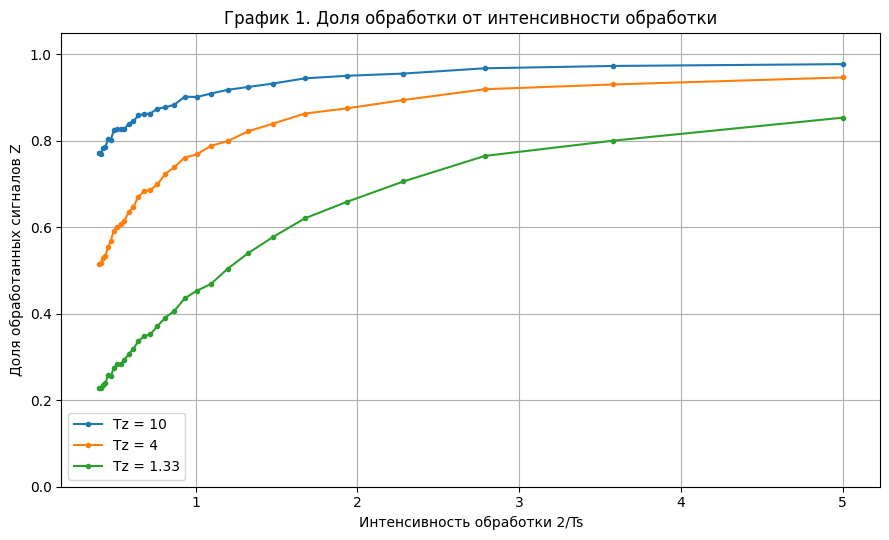

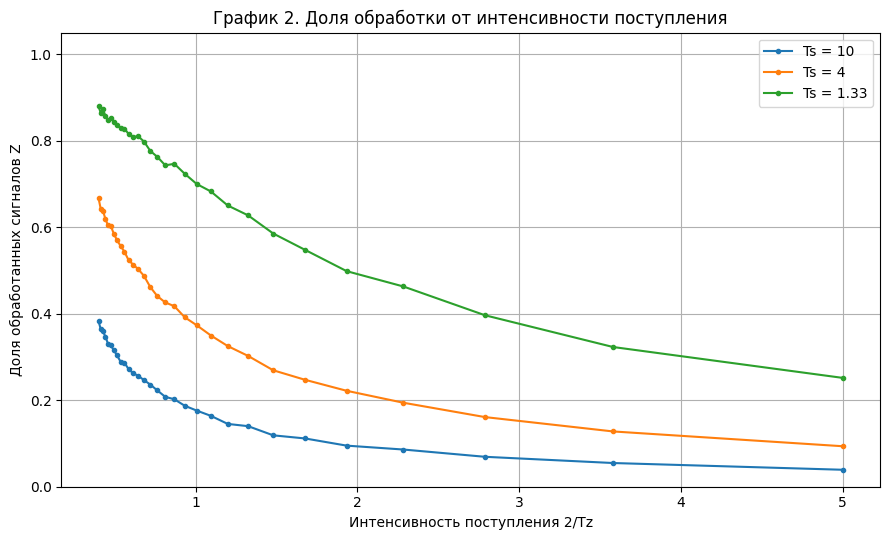

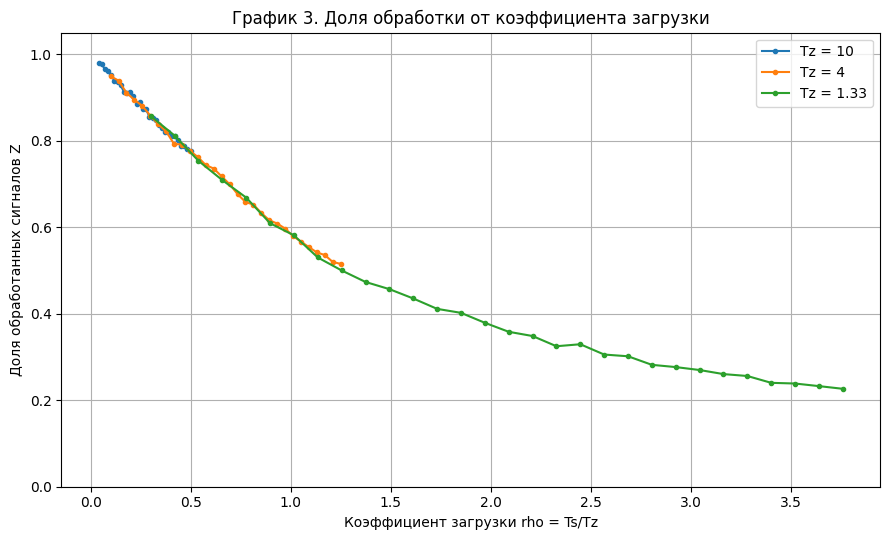

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Количество сигналов в каждом эксперименте
N_GRAPH = 5000

# Исходные параметры из методички
T_VALUES = [10, 4, 1.33]

# Значения Ts и Tz для построения графиков
values = np.linspace(0.4, 5, 30)

def experiment(Tz, Ts, seed):
    result = simulate(Tz, Ts, n=N_GRAPH, seed=seed)
    return result["Доля обработанных"]

# --------------------------------------------------
# ГРАФИК 1. Доля обработанных от интенсивности
# обработки: 2/Ts
# --------------------------------------------------

plt.figure(figsize=(9, 5.5))

for Tz in T_VALUES:
    x = []
    y = []

    for i, Ts in enumerate(values):
        z = experiment(Tz, Ts, seed=1000 + i)
        x.append(2 / Ts)
        y.append(z)

    # Сортируем точки по горизонтальной оси
    order = np.argsort(x)
    plt.plot(
        np.array(x)[order],
        np.array(y)[order],
        marker="o",
        markersize=3,
        label=f"Tz = {Tz}"
    )

plt.xlabel("Интенсивность обработки 2/Ts")
plt.ylabel("Доля обработанных сигналов Z")
plt.title("График 1. Доля обработки от интенсивности обработки")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# ГРАФИК 2. Доля обработанных от интенсивности
# поступления: 2/Tz
# --------------------------------------------------

plt.figure(figsize=(9, 5.5))

for Ts in T_VALUES:
    x = []
    y = []

    for i, Tz in enumerate(values):
        z = experiment(Tz, Ts, seed=2000 + i)
        x.append(2 / Tz)
        y.append(z)

    order = np.argsort(x)
    plt.plot(
        np.array(x)[order],
        np.array(y)[order],
        marker="o",
        markersize=3,
        label=f"Ts = {Ts}"
    )

plt.xlabel("Интенсивность поступления 2/Tz")
plt.ylabel("Доля обработанных сигналов Z")
plt.title("График 2. Доля обработки от интенсивности поступления")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# ГРАФИК 3. Доля обработанных от коэффициента
# загрузки rho = Ts/Tz
# --------------------------------------------------

plt.figure(figsize=(9, 5.5))

for Tz in T_VALUES:
    x = []
    y = []

    for i, Ts in enumerate(values):
        z = experiment(Tz, Ts, seed=3000 + i)
        x.append(Ts / Tz)
        y.append(z)

    order = np.argsort(x)
    plt.plot(
        np.array(x)[order],
        np.array(y)[order],
        marker="o",
        markersize=3,
        label=f"Tz = {Tz}"
    )

plt.xlabel("Коэффициент загрузки rho = Ts/Tz")
plt.ylabel("Доля обработанных сигналов Z")
plt.title("График 3. Доля обработки от коэффициента загрузки")
plt.ylim(0, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()